# 01b · Redraw the Stage 0 causal graphs with Graphviz (seconds, no rerun)

**What this step does.** Redraws each Stage 0 DAG from the saved `edges_*.csv`, using Graphviz's layered layout, which separates the boxes, routes the arrows around them and prints each edge's coefficient. Stage 0 itself is **not** rerun.

**Why.** The matplotlib fallback crams the boxes onto one row, so labels overlap and edges can't be read. Graphviz is the renderer the Stage 0 script was designed for.

**Needs (one time):** the **Graphviz program** (it provides `dot.exe`), not only the Python package. The first code cell checks for it and tells you what to do if it's missing.

**Two views per dataset:**
- *focused* (`fig_stage0_dag_<tag>.png`): only the protected attributes, the label, the label's parents and the paths between them. **Use this one in the paper.**
- *full* (`fig_stage0_dag_<tag>_full.png`): every edge that passed the filter.

**Decluttering:** with ~30,000 rows almost every edge is "reliably present", so `MIN_COEF` hides edges whose effect is tiny (|standardized coefficient| below it). Try 0.05; state the value in the figure caption.

In [1]:
# --- setup: run this cell first -------------------------------------------
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd
sys.path.insert(0, str(Path.cwd()))          # li_lib.py sits next to the notebooks
import li_lib as li
pd.set_option("display.width", 160, "display.max_columns", 30)
print("li_lib", li.VERSION, "| project folder:", li.ROOT)
li.versions()

li_lib 1.1.0 | project folder: D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity


,package,version
0,numpy,2.2.6
1,pandas,3.0.6
2,scikit-learn,1.9.1
3,xgboost,3.4.1
4,cleanlab,2.9.0
5,lingam,1.13.0
6,causal-learn,0.1.4.8


In [2]:
import os, importlib.util
# Graphviz's usual Windows install folder; added to PATH for this notebook only
for d in (r"C:\Program Files\Graphviz\bin", r"C:\Program Files (x86)\Graphviz\bin"):
    if os.path.isdir(d) and d not in os.environ["PATH"]:
        os.environ["PATH"] += os.pathsep + d
import graphviz
try:
    print("Graphviz found, version", ".".join(map(str, graphviz.version())))
except Exception as e:
    print("!! Graphviz program NOT found:", e)
    print("   Install it in PowerShell:  winget install graphviz")
    print("   (or download the Windows installer from https://graphviz.org/download/ and tick 'add to PATH')")
    print("   Then restart PyCharm and rerun this cell.")
spec = importlib.util.spec_from_file_location("stage0_diagnose", li.STAGE0_SCRIPT)
s0 = importlib.util.module_from_spec(spec); sys.modules["stage0_diagnose"] = s0; spec.loader.exec_module(s0)

Graphviz found, version 14.1.5


[stage0 12:52:06] wrote D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\stage0_out\diabetes130\fig_stage0_dag_Diab.pdf/.png (6 nodes, graphviz; P>=0.5, |b|>=0.05)
[stage0 12:52:07] wrote D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\stage0_out\diabetes130\fig_stage0_dag_Diab_full.pdf/.png (18 nodes, graphviz; P>=0.5, |b|>=0.05)
[stage0 12:52:07] edge summary at P>=0.5: 85 edges; |b| quartiles [0.029, 0.048, 0.106]; 42 with |b|>=0.05, 23 with |b|>=0.10
== diabetes130: focused view


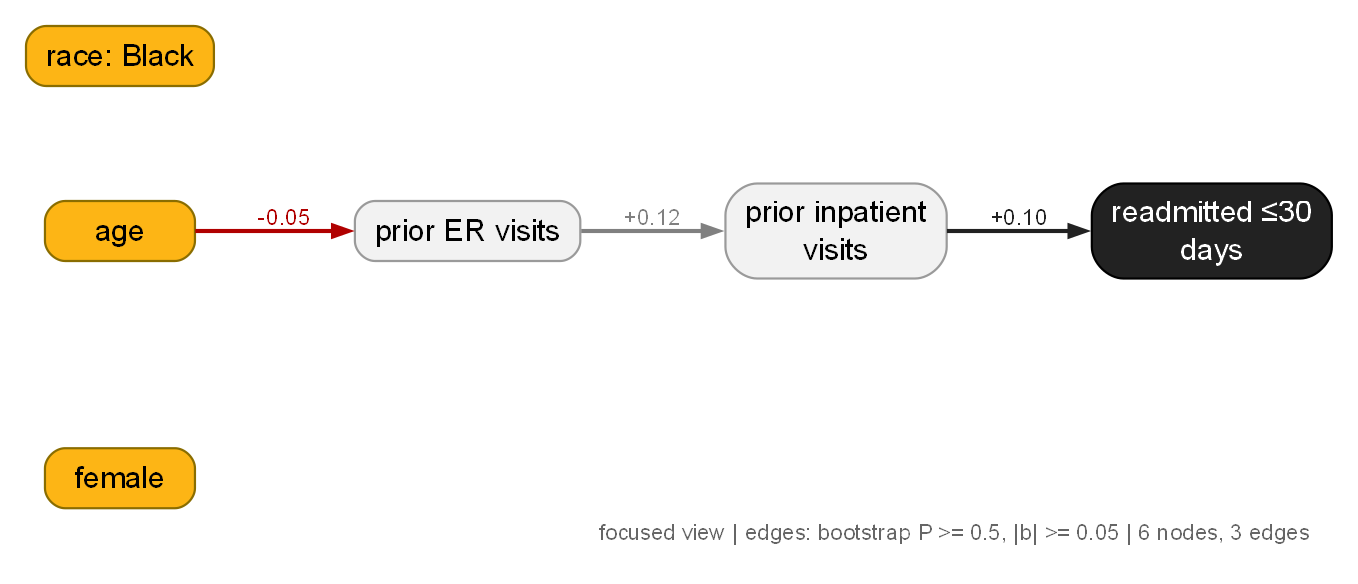

[stage0 12:52:08] wrote D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\stage0_out\cdcdiabetes\fig_stage0_dag_CDC.pdf/.png (21 nodes, graphviz; P>=0.5, |b|>=0.05)
[stage0 12:52:09] wrote D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\stage0_out\cdcdiabetes\fig_stage0_dag_CDC_full.pdf/.png (22 nodes, graphviz; P>=0.5, |b|>=0.05)
[stage0 12:52:09] edge summary at P>=0.5: 159 edges; |b| quartiles [0.03, 0.057, 0.097]; 88 with |b|>=0.05, 39 with |b|>=0.10
== cdcdiabetes: focused view


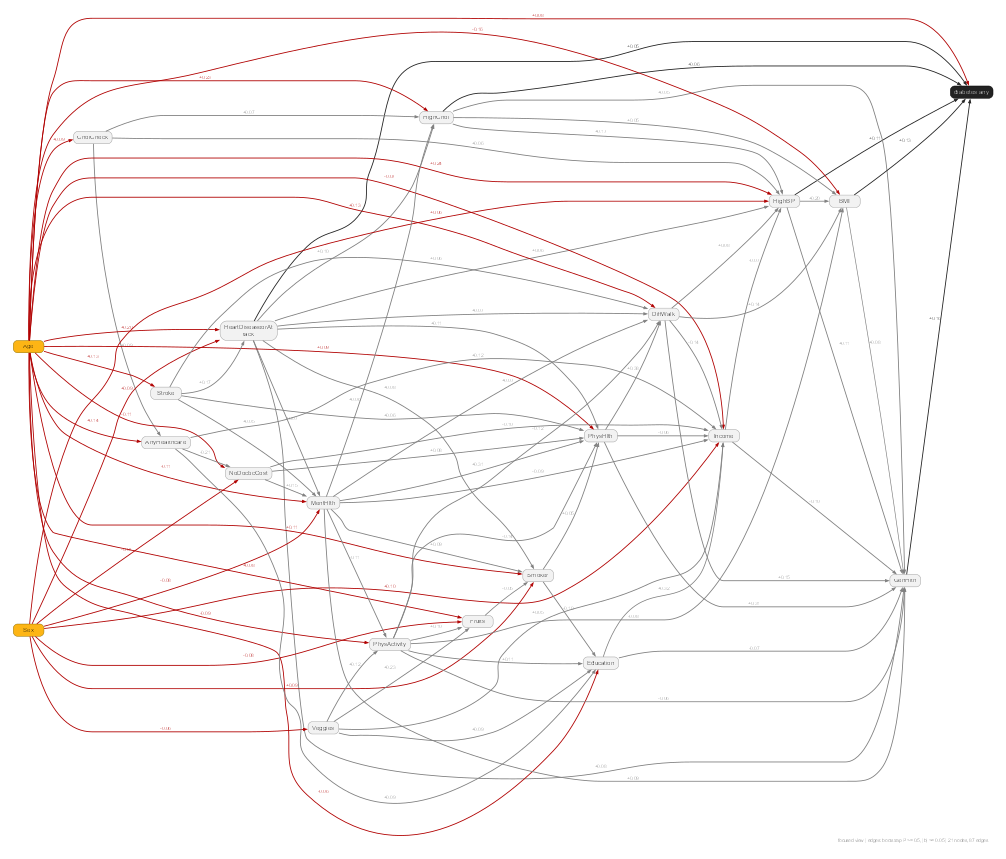

[stage0 12:52:10] wrote D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\stage0_out\taiwancredit\fig_stage0_dag_TWN.pdf/.png (16 nodes, graphviz; P>=0.5, |b|>=0.05)
[stage0 12:52:11] wrote D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\stage0_out\taiwancredit\fig_stage0_dag_TWN_full.pdf/.png (16 nodes, graphviz; P>=0.5, |b|>=0.05)
[stage0 12:52:11] edge summary at P>=0.5: 79 edges; |b| quartiles [0.036, 0.068, 0.115]; 44 with |b|>=0.05, 24 with |b|>=0.10
== taiwancredit: focused view


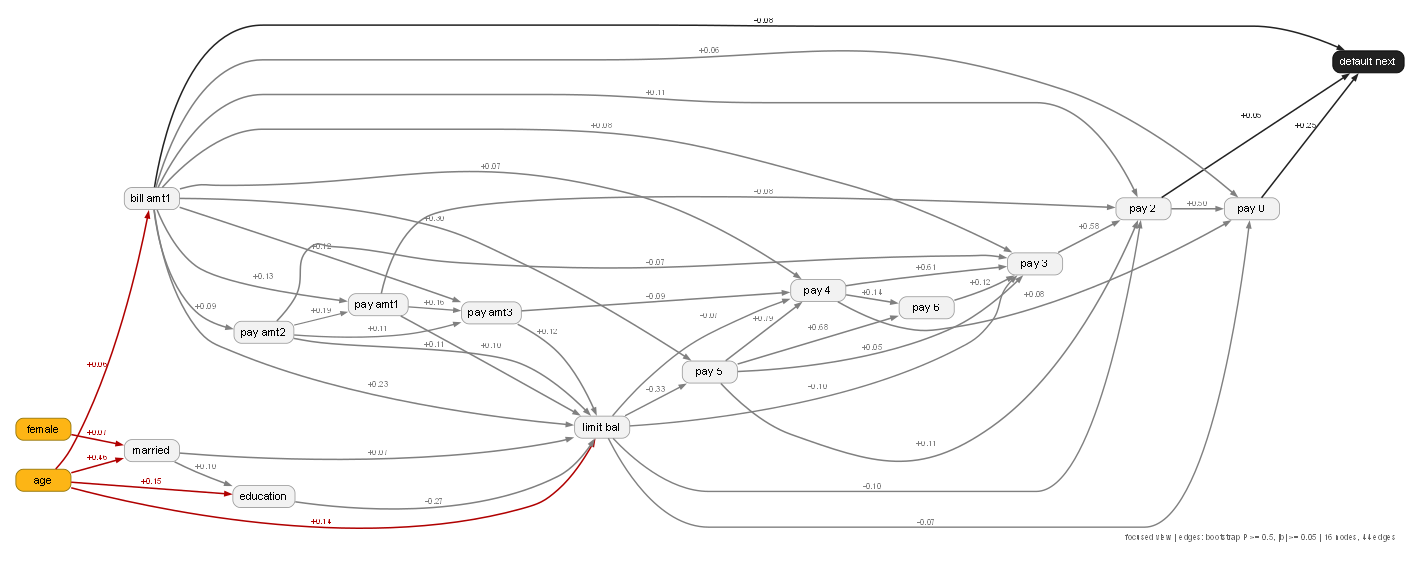

In [3]:
MIN_COEF = 0.05      # hide edges with |std. coefficient| below this (0.0 = show all)
STAMP = True         # False = no filter note under the figure (final paper version)
from IPython.display import Image, display
TAGS = {"diabetes130": "Diab", "cdcdiabetes": "CDC", "taiwancredit": "TWN"}   # South German Credit retired Oct 10
for name, tag in TAGS.items():
    run = li.STAGE0 / name
    if not (run / f"edges_{tag}.csv").exists():
        print(f"-- {name}: no Stage 0 output yet (run notebook 01 first)"); continue
    args = ["redraw", "--run", str(run), "--tag", tag, "--engine", "graphviz",
            "--min-coef", str(MIN_COEF), "--width", "7"] + ([] if STAMP else ["--no-stamp"])
    s0.main(args)
    print(f"== {name}: focused view")
    display(Image(filename=str(run / f"fig_stage0_dag_{tag}.png")))

## What to look for
- [ ] Arrows from the protected attributes (gold boxes) through other variables into the label (black box).
- [ ] The numbers on the edges are standardized coefficients: +0.16 means a one-standard-deviation increase in the parent moves the child up 0.16 standard deviations.
- [ ] For CDC, whether `AnyHealthcare` or `NoDocbcCost` has a path into the label.
- [ ] If the focused view is still crowded, raise `MIN_COEF` to 0.08-0.10 and rerun this cell.